# TRUSTSR Lab 02.05 — Concurrent Checkpoints and Atomic High-Water Mark

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Phase:** Lab 02 — Recovery implementation  
**Status:** Synthetic simulation / research prototype  
**Version:** 0.1.0

## Connection to Lab 02.04
Lab 02.04 used an in-memory version gate to reject stale signed checkpoints. That implementation was single-threaded: two concurrent requests could both read the same high-water mark and both pass a check before either update becomes visible. This lab models that race and compares it with a lock-protected atomic check-and-update.

## Policies compared
- **Naive policy:** read the high-water mark, compare the checkpoint version, then update without a lock. The check/update sequence is deliberately split to expose a race.
- **Atomic policy:** validate signature and version, then perform compare-and-update under a lock. Only one candidate can advance the mark at a time.
- The simulation uses signed checkpoints and a trusted public key created within this notebook session.

## Scenarios
1. Two concurrent submissions with the same version.
2. Two concurrent submissions with different versions.
3. A stale version competing with a newer version.
4. Simulated persistence failure before commit.
5. Invalid signature.

## Evidence boundary
This is a **synthetic concurrency simulation**, not a benchmark of a production database or distributed system. Python threads and in-memory state do not establish crash consistency, distributed consensus, durable storage guarantees, or correctness under process failure. Results depend on the simulated interleaving. All findings must be described as simulated outcomes.

## 1. Install dependencies and import

In [1]:
%pip -q install cryptography pandas matplotlib

In [2]:
import sys, platform, json, copy, threading, time
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
from cryptography.exceptions import InvalidSignature

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("cryptography:", __import__("cryptography").__version__)
print("Pandas:", pd.__version__)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence type: synthetic concurrency simulation only")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
cryptography: 46.0.6
Pandas: 3.0.2
Execution UTC: 2026-10-11T10:26:32.953909+00:00
Evidence type: synthetic concurrency simulation only


## 2. Build signed checkpoint fixtures

In [3]:
private_key = Ed25519PrivateKey.generate()
public_key = private_key.public_key()

def canonical_bytes(obj):
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode("utf-8")

def make_checkpoint(version, value):
    return {
        "schema_version": 1,
        "checkpoint_version": version,
        "state": {"M1": value},
    }

def sign_checkpoint(checkpoint):
    return {"checkpoint": copy.deepcopy(checkpoint),
            "signature": private_key.sign(canonical_bytes(checkpoint))}

def verify_signed(signed):
    try:
        public_key.verify(signed["signature"], canonical_bytes(signed["checkpoint"]))
        return True
    except (InvalidSignature, KeyError, TypeError):
        return False

signed = {v: sign_checkpoint(make_checkpoint(v, f"synthetic state version {v}")) for v in range(1, 6)}
assert all(verify_signed(item) for item in signed.values())
print("Prepared signed versions:", sorted(signed))
print("Signature fixture assertions passed.")

Prepared signed versions: [1, 2, 3, 4, 5]
Signature fixture assertions passed.


## 3. Deterministic race: naive check-then-update

In [4]:
def naive_concurrent_trial(initial_mark, candidate_versions, fail_before_commit=False):
    # Barrier forces both workers to read the same mark before either writes.
    barrier = threading.Barrier(len(candidate_versions))
    shared = {"mark": initial_mark, "accepted": [], "lock": threading.Lock()}
    outcomes = []

    def worker(version):
        signed_item = signed[version]
        if not verify_signed(signed_item):
            outcomes.append({"version": version, "accepted": False, "reason": "invalid_signature"})
            return
        observed_mark = shared["mark"]  # intentionally unprotected read
        eligible = version > observed_mark
        barrier.wait()
        if not eligible:
            outcomes.append({"version": version, "accepted": False, "reason": "stale_at_read"})
            return
        # Simulated persistence failure occurs before writing.
        if fail_before_commit:
            outcomes.append({"version": version, "accepted": False, "reason": "simulated_persistence_failure"})
            return
        shared["mark"] = version  # intentionally unprotected write
        outcomes.append({"version": version, "accepted": True, "reason": "accepted_naive"})

    threads = [threading.Thread(target=worker, args=(v,)) for v in candidate_versions]
    for t in threads: t.start()
    for t in threads: t.join()
    return shared["mark"], outcomes

naive_same_mark, naive_same_outcomes = naive_concurrent_trial(1, [3, 3])
print("Naive same-version mark:", naive_same_mark)
print("Naive outcomes:", naive_same_outcomes)
print("Note: both workers may report acceptance despite submitting the same version.")

Naive same-version mark: 3
Naive outcomes: [{'version': 3, 'accepted': True, 'reason': 'accepted_naive'}, {'version': 3, 'accepted': True, 'reason': 'accepted_naive'}]
Note: both workers may report acceptance despite submitting the same version.


## 4. Atomic version gate using a lock

In [5]:
class AtomicVersionGate:
    def __init__(self, high_water_mark=0):
        self.high_water_mark = high_water_mark
        self.lock = threading.Lock()

    def consider(self, signed_checkpoint, simulate_persistence_failure=False):
        if not verify_signed(signed_checkpoint):
            return {"accepted": False, "reason": "invalid_signature",
                    "high_water_mark": self.high_water_mark}
        checkpoint = signed_checkpoint["checkpoint"]
        version = checkpoint.get("checkpoint_version")
        if not isinstance(version, int) or isinstance(version, bool) or version < 1:
            return {"accepted": False, "reason": "invalid_version",
                    "high_water_mark": self.high_water_mark}

        with self.lock:
            before = self.high_water_mark
            if version <= before:
                return {"accepted": False, "reason": "replay_or_stale_version",
                        "high_water_mark": self.high_water_mark}
            # Simulate a failure before commit: mark must not advance.
            if simulate_persistence_failure:
                return {"accepted": False, "reason": "simulated_persistence_failure",
                        "high_water_mark": self.high_water_mark}
            self.high_water_mark = version
            return {"accepted": True, "reason": "accepted_atomically",
                    "high_water_mark": self.high_water_mark}

def run_atomic_concurrent(initial_mark, candidate_versions, failure_version=None):
    gate = AtomicVersionGate(initial_mark)
    barrier = threading.Barrier(len(candidate_versions))
    results = []
    result_lock = threading.Lock()

    def worker(version):
        barrier.wait()
        result = gate.consider(signed[version], simulate_persistence_failure=(version == failure_version))
        result["version"] = version
        with result_lock:
            results.append(result)

    threads = [threading.Thread(target=worker, args=(v,)) for v in candidate_versions]
    for t in threads: t.start()
    for t in threads: t.join()
    return gate.high_water_mark, results

atomic_same_mark, atomic_same_results = run_atomic_concurrent(1, [3, 3])
print("Atomic same-version mark:", atomic_same_mark)
print("Atomic outcomes:", atomic_same_results)

Atomic same-version mark: 3
Atomic outcomes: [{'accepted': True, 'reason': 'accepted_atomically', 'high_water_mark': 3, 'version': 3}, {'accepted': False, 'reason': 'replay_or_stale_version', 'high_water_mark': 3, 'version': 3}]


## 5. Compare controlled scenarios

In [6]:
scenario_rows = []

# Same version race: naive and atomic.
mark, outs = naive_concurrent_trial(1, [3, 3])
scenario_rows.append({
    "scenario": "same_version_race", "policy": "naive",
    "candidate_count": 2, "accepted_count": sum(x["accepted"] for x in outs),
    "final_mark": mark, "duplicate_acceptance": sum(x["accepted"] for x in outs) > 1,
})
mark, outs = run_atomic_concurrent(1, [3, 3])
scenario_rows.append({
    "scenario": "same_version_race", "policy": "atomic",
    "candidate_count": 2, "accepted_count": sum(x["accepted"] for x in outs),
    "final_mark": mark, "duplicate_acceptance": sum(x["accepted"] for x in outs) > 1,
})

# Different versions racing: both may be accepted by naive policy; atomic permits only increasing commits.
mark, outs = naive_concurrent_trial(1, [2, 4])
scenario_rows.append({
    "scenario": "different_versions_race", "policy": "naive",
    "candidate_count": 2, "accepted_count": sum(x["accepted"] for x in outs),
    "final_mark": mark, "duplicate_acceptance": False,
})
mark, outs = run_atomic_concurrent(1, [2, 4])
scenario_rows.append({
    "scenario": "different_versions_race", "policy": "atomic",
    "candidate_count": 2, "accepted_count": sum(x["accepted"] for x in outs),
    "final_mark": mark, "duplicate_acceptance": False,
})

# Persistence failure must not advance the high-water mark.
gate_fail = AtomicVersionGate(2)
failure_result = gate_fail.consider(signed[4], simulate_persistence_failure=True)
scenario_rows.append({
    "scenario": "persistence_failure", "policy": "atomic",
    "candidate_count": 1, "accepted_count": int(failure_result["accepted"]),
    "final_mark": gate_fail.high_water_mark, "duplicate_acceptance": False,
})

# Invalid signature must be rejected.
bad = copy.deepcopy(signed[5])
bad["checkpoint"]["state"]["M1"] = "tampered"
gate_bad = AtomicVersionGate(2)
bad_result = gate_bad.consider(bad)
scenario_rows.append({
    "scenario": "invalid_signature", "policy": "atomic",
    "candidate_count": 1, "accepted_count": int(bad_result["accepted"]),
    "final_mark": gate_bad.high_water_mark, "duplicate_acceptance": False,
})

scenario_df = pd.DataFrame(scenario_rows)
display(scenario_df)

                  scenario  policy  candidate_count  accepted_count  final_mark  duplicate_acceptance
0        same_version_race   naive                2               2           3                  True
1        same_version_race  atomic                2               1           3                 False
2  different_versions_race   naive                2               2           2                 False
3  different_versions_race  atomic                2               1           4                 False
4      persistence_failure  atomic                1               0           2                 False
5        invalid_signature  atomic                1               0           2                 False

## 6. Measure acceptance and race indicators

In [7]:
summary_df = scenario_df.groupby(["scenario", "policy"], as_index=False).agg(
    candidates=("candidate_count", "sum"),
    accepted=("accepted_count", "sum"),
    final_mark=("final_mark", "max"),
    duplicate_acceptance=("duplicate_acceptance", "max"),
)
summary_df["rejected"] = summary_df["candidates"] - summary_df["accepted"]
display(summary_df)

# For same-version race, this specific barrier-controlled naive implementation should show
# two acceptances; the atomic gate should accept one and reject the duplicate.
naive_duplicate = summary_df.query("scenario == 'same_version_race' and policy == 'naive'")["accepted"].iloc[0]
atomic_duplicate = summary_df.query("scenario == 'same_version_race' and policy == 'atomic'")["accepted"].iloc[0]
print("Same-version accepted count — naive:", naive_duplicate)
print("Same-version accepted count — atomic:", atomic_duplicate)

                  scenario  policy  candidates  accepted  final_mark  duplicate_acceptance  rejected
0  different_versions_race  atomic           2         1           4                 False         1
1  different_versions_race   naive           2         2           2                 False         0
2        invalid_signature  atomic           1         0           2                 False         1
3      persistence_failure  atomic           1         0           2                 False         1
4        same_version_race  atomic           2         1           3                 False         1
5        same_version_race   naive           2         2           3                  True         0

Same-version accepted count — naive: 2
Same-version accepted count — atomic: 1


## 7. Plot synthetic comparison

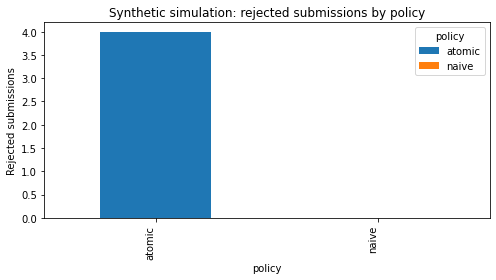

In [8]:
pivot = summary_df.pivot(index="scenario", columns="policy", values="accepted").fillna(0)
ax = pivot.plot(kind="bar", figsize=(10, 5))
ax.set_ylabel("Accepted submissions")
ax.set_title("Synthetic simulation: accepted submissions by concurrency policy")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

ax = summary_df.groupby("policy")["rejected"].sum().plot(kind="bar", figsize=(7, 4))
ax.set_ylabel("Rejected submissions")
ax.set_title("Synthetic simulation: rejected submissions by policy")
plt.tight_layout()
plt.show()

## 8. Assertions

In [9]:
assert naive_duplicate == 2, "Expected the barrier-controlled naive race to accept both duplicate versions."
assert atomic_duplicate == 1, "Atomic gate must accept only one of two identical versions."
assert gate_fail.high_water_mark == 2, "Simulated persistence failure must not advance the mark."
assert not bad_result["accepted"] and bad_result["reason"] == "invalid_signature"
assert gate_bad.high_water_mark == 2, "Invalid signature must not advance the mark."
assert all(verify_signed(item) for item in signed.values())

# Test atomic gate sequentially: a version can advance the mark, then a stale replay is rejected.
seq_gate = AtomicVersionGate(1)
assert seq_gate.consider(signed[3])["accepted"]
replay_result = seq_gate.consider(signed[2])
assert not replay_result["accepted"] and replay_result["reason"] == "replay_or_stale_version"
assert seq_gate.high_water_mark == 3

print("PASS: naive race demonstrates duplicate acceptance in this controlled interleaving.")
print("PASS: atomic gate accepts only one of two same-version submissions.")
print("PASS: simulated persistence failure leaves high-water mark unchanged.")
print("PASS: invalid signature is rejected without state advancement.")
print("PASS: stale replay rejected after atomic advancement.")
print("All Lab 02.05 assertions passed.")

PASS: naive race demonstrates duplicate acceptance in this controlled interleaving.
PASS: atomic gate accepts only one of two same-version submissions.
PASS: simulated persistence failure leaves high-water mark unchanged.
PASS: invalid signature is rejected without state advancement.
PASS: stale replay rejected after atomic advancement.
All Lab 02.05 assertions passed.


## 9. Export CSV artifacts

In [10]:
scenario_df.to_csv("trustsr_lab02_05_concurrency_scenarios.csv", index=False)
summary_df.to_csv("trustsr_lab02_05_concurrency_summary.csv", index=False)
print("Generated files:")
print("- trustsr_lab02_05_concurrency_scenarios.csv")
print("- trustsr_lab02_05_concurrency_summary.csv")

Generated files:
- trustsr_lab02_05_concurrency_scenarios.csv
- trustsr_lab02_05_concurrency_summary.csv


## 10. Interpretation and limitations

### What this simulation demonstrates
In the deliberately barrier-controlled naive implementation, two workers can both read the same prior high-water mark and both accept the same version. The lock-protected gate serializes the check-and-update, so only the first same-version submission advances the mark; the second is rejected as stale/replay.

### Important qualification
This is a designed race demonstration, not an empirical performance benchmark. The barrier deliberately creates the unsafe interleaving. The lock provides mutual exclusion only within this single Python process; it does not provide durable atomicity across crashes, multiple machines, or independent services.

### Production requirements not implemented
- Durable transactional storage with a unique/conditional version update.
- Crash recovery and commit acknowledgement semantics.
- Distributed coordination across multiple workers or replicas.
- Key rotation/revocation and independent public-key trust.
- Idempotency keys and request-level audit logging.
- Real-agent traces or an independently reproducible benchmark.

### Next research step
Lab 02.06 should move the high-water mark to a transactional store or a faithful local database model and test atomic compare-and-swap, rollback after failed transactions, and recovery after process restart. Label all outputs as synthetic until measured in a real, documented implementation.